# Week 3: Hospital Operations, Cost & Patient Flow Intelligence
**Track B: Data Science — Statistical Investigation & Insight Discovery**
# Reyhana abdikher Somo

## 1. Environment Setup & Data Ingestion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure plotting style
sns.set_theme(style="whitegrid")

# Helper function to load CSVs and strip UTF-8 BOM characters
def load_clean_csv(path):
    df = pd.read_csv(path, encoding='latin1')
    df.columns = [c.encode('latin1').decode('utf-8', errors='ignore').strip().lstrip('\ufeff') for c in df.columns]
    # Ensure any corrupted 'Id' or 'START' first column is cleanly named
    if df.columns[0].endswith('Id'):
        df.rename(columns={df.columns[0]: 'Id'}, inplace=True)
    elif df.columns[0].endswith('START'):
        df.rename(columns={df.columns[0]: 'START'}, inplace=True)
    return df

encounters = load_clean_csv('encounters.csv')
patients = load_clean_csv('patients.csv')
procedures = load_clean_csv('procedures.csv')
payers = load_clean_csv('payers.csv')
organizations = load_clean_csv('organizations.csv')

print(f"Encounters: {encounters.shape}")
print(f"Patients: {patients.shape}")
print(f"Procedures: {procedures.shape}")
print(f"Payers: {payers.shape}")
print(f"Organizations: {organizations.shape}")

Encounters: (12749, 14)
Patients: (974, 20)
Procedures: (14009, 9)
Payers: (10, 7)
Organizations: (1, 8)


## 2. Data Quality Assessment & Feature Engineering
* Checks for duplicates, missing values, and referential integrity across tables.
* Excludes personally identifiable information (`FIRST`, `LAST`, `ADDRESS`, `LAT`, `LON`) from analysis.
* Engineers `DURATION_HOURS` and `YEAR` features.

In [2]:
# Check duplicate records and referential integrity
print("Duplicate encounters:", encounters.duplicated().sum())
print("Duplicate procedures:", procedures.duplicated().sum())
print("Unmatched patient IDs:", (~encounters['PATIENT'].isin(patients['Id'])).sum())
print("Unmatched payer IDs:", (~encounters['PAYER'].isin(payers['Id'])).sum())
print("Unmatched procedure encounter IDs:", (~procedures['ENCOUNTER'].isin(encounters['Id'])).sum())

# Parse timestamps and compute encounter duration in hours
encounters['START'] = pd.to_datetime(encounters['START'])
encounters['STOP'] = pd.to_datetime(encounters['STOP'])
encounters['DURATION_HOURS'] = (encounters['STOP'] - encounters['START']).dt.total_seconds() / 3600.0
encounters['YEAR'] = encounters['START'].dt.year

# Join payer names (strictly omitting patient PII)
df = encounters.merge(
    payers[['Id', 'NAME']],
    left_on='PAYER',
    right_on='Id',
    how='left',
    suffixes=('', '_PAYER')
)

print("\nDate Range:", df['START'].min(), "to", df['STOP'].max())
print("Negative durations:", (df['DURATION_HOURS'] < 0).sum())

Duplicate encounters: 0
Duplicate procedures: 0
Unmatched patient IDs: 0
Unmatched payer IDs: 0
Unmatched procedure encounter IDs: 0

Date Range: 2011-01-02 09:26:36+00:00 to 2020-02-01 13:49:08+00:00
Negative durations: 0


## 3. Exploratory Data Analysis & SQL Reconciliation Metrics

In [3]:
# 3.1 Annual Encounter Volume & Encounter Class Share
print("--- Encounters by Year ---")
print(df['YEAR'].value_counts().sort_index())

print("\n--- Encounter Class Distribution (%) ---")
class_dist = pd.DataFrame({
    'Count': df['ENCOUNTERCLASS'].value_counts(),
    'Percentage (%)': (df['ENCOUNTERCLASS'].value_counts(normalize=True) * 100).round(2)
})
print(class_dist)

# 3.2 Duration > 24 Hours & Zero Payer Coverage
over_24 = (df['DURATION_HOURS'] > 24).sum()
zero_cov = (df['PAYER_COVERAGE'] == 0).sum()
print(f"\nEncounters > 24 hours: {over_24:,} ({over_24 / len(df) * 100:.2f}%)")
print(f"Zero payer coverage encounters: {zero_cov:,} ({zero_cov / len(df) * 100:.2f}%)")

# 3.3 30-Day Repeat Encounters
df_sorted = df.sort_values(['PATIENT', 'START']).copy()
df_sorted['PREV_STOP'] = df_sorted.groupby('PATIENT')['STOP'].shift(1)
df_sorted['DAYS_SINCE_PREV'] = (df_sorted['START'] - df_sorted['PREV_STOP']).dt.total_seconds() / 86400.0
repeat_30 = df_sorted[(df_sorted['DAYS_SINCE_PREV'] >= 0) & (df_sorted['DAYS_SINCE_PREV'] <= 30)]
print(f"30-Day Repeat Encounters: {len(repeat_30):,} across {repeat_30['PATIENT'].nunique()} unique patients")

--- Encounters by Year ---
YEAR
2011    1336
2012    2106
2013    2495
2014    3885
2015    2469
2016     458
Name: count, dtype: int64

--- Encounter Class Distribution (%) ---
                Count  Percentage (%)
ENCOUNTERCLASS                       
ambulatory       6292           49.35
outpatient       2552           20.02
urgentcare       1455           11.41
emergency         958            7.51
wellness          940            7.37
inpatient         552            4.33

Encounters > 24 hours: 30 (0.24%)
Zero payer coverage encounters: 6,393 (50.15%)
30-Day Repeat Encounters: 7,567 across 541 unique patients


## 4. Formal Hypothesis Testing (Non-Parametric)
Because `TOTAL_CLAIM_COST` and `DURATION_HOURS` exhibit extreme right-skewness, non-parametric tests (Kruskal-Wallis H-test and Spearman rank correlation) are applied at $\alpha = 0.05$.

In [4]:
# Hypothesis 1: Total Claim Cost across Encounter Classes
class_groups = [g['TOTAL_CLAIM_COST'].values for _, g in df.groupby('ENCOUNTERCLASS')]
h1_stat, h1_p = stats.kruskal(*class_groups)
print(f"H1 Kruskal-Wallis (Cost by Encounter Class): H = {h1_stat:.2f}, p = {h1_p:.4e}")
print(df.groupby('ENCOUNTERCLASS')['TOTAL_CLAIM_COST'].agg(['count', 'mean', 'median', 'std']).round(2))

# Hypothesis 2: Monotonic Association between Encounter Duration and Total Claim Cost
h2_rho, h2_p = stats.spearmanr(df['DURATION_HOURS'], df['TOTAL_CLAIM_COST'])
print(f"\nH2 Spearman Rank Correlation (Duration vs. Cost): rho = {h2_rho:.4f}, p = {h2_p:.4e}")

# Hypothesis 3: Total Claim Cost across Payers
payer_groups = [g['TOTAL_CLAIM_COST'].values for _, g in df.groupby('NAME')]
h3_stat, h3_p = stats.kruskal(*payer_groups)
print(f"\nH3 Kruskal-Wallis (Cost by Payer): H = {h3_stat:.2f}, p = {h3_p:.4e}")
print(df.groupby('NAME')['TOTAL_CLAIM_COST'].agg(['count', 'mean', 'median', 'std']).sort_values('mean', ascending=False).round(2))

H1 Kruskal-Wallis (Cost by Encounter Class): H = 1079.90, p = 3.0161e-231
                count     mean    median       std
ENCOUNTERCLASS                                    
ambulatory       6292  3012.02    573.98   7265.62
emergency         958  4191.48    146.18   8590.17
inpatient         552  8914.63  10138.58   7708.28
outpatient       2552  2264.86    269.94   5560.62
urgentcare       1455  6654.97    142.58  11369.61
wellness          940  3943.99   1225.32   7857.64

H2 Spearman Rank Correlation (Duration vs. Cost): rho = 0.3386, p = 0.0000e+00

H3 Kruskal-Wallis (Cost by Payer): H = 942.08, p = 5.2901e-197
                        count     mean   median       std
NAME                                                     
Medicaid                  735  6575.67  1336.76  10622.69
NO_INSURANCE             4208  5237.61   982.70   9026.95
Blue Cross Blue Shield    429  3529.30   277.49   8529.25
UnitedHealthcare          455  3368.28   459.31   7827.56
Anthem                    

## 5. Visualizations (5 Required Figures)

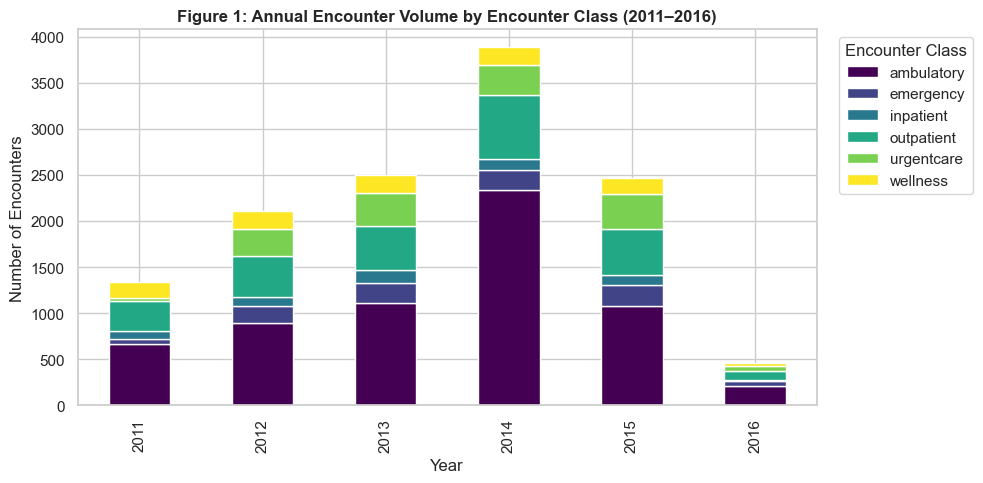

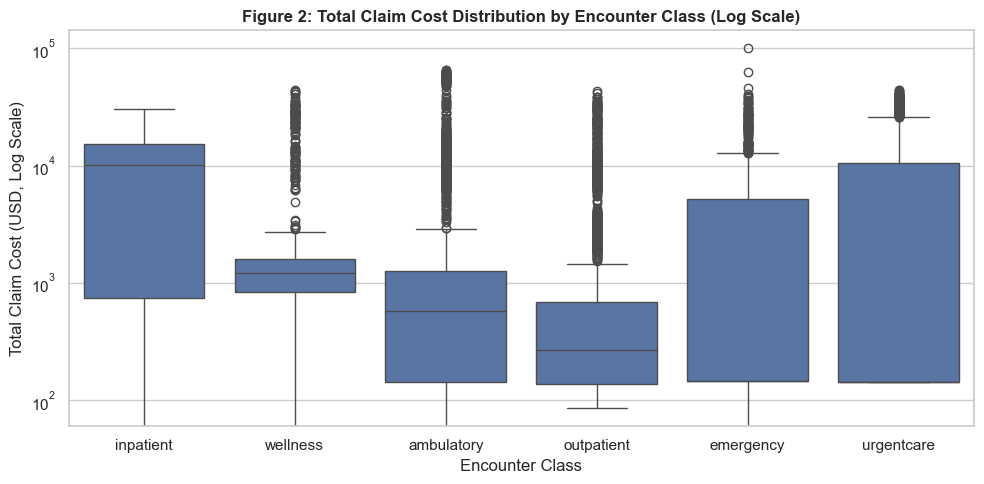

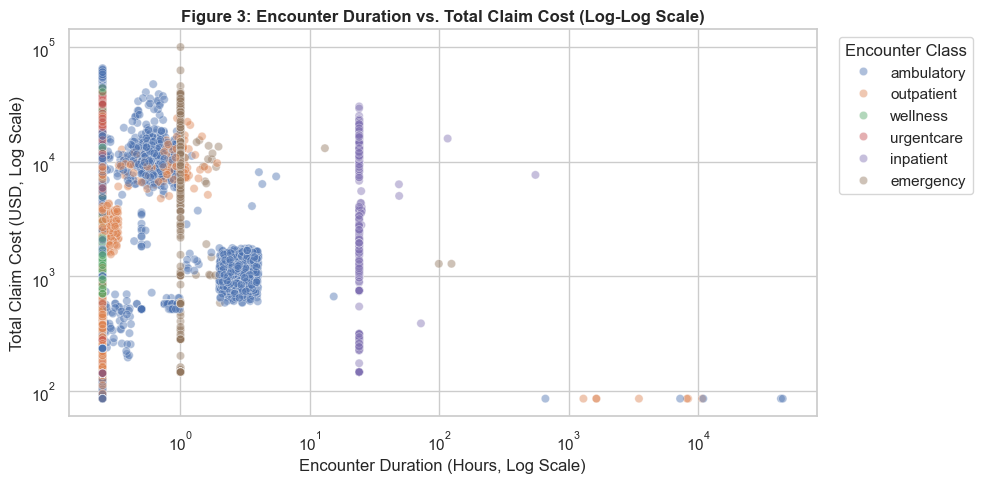

In [5]:
# Figure 1: Annual Encounter Volume by Encounter Class
fig, ax = plt.subplots(figsize=(10, 5))
df.groupby(['YEAR', 'ENCOUNTERCLASS']).size().unstack(fill_value=0).plot(
    kind='bar', stacked=True, ax=ax, colormap='viridis'
)
ax.set_title('Figure 1: Annual Encounter Volume by Encounter Class (2011–2016)', fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Number of Encounters')
ax.legend(title='Encounter Class', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('fig1_encounter_volumes.png', dpi=150)
plt.show()

# Figure 2: Distribution of Total Claim Cost by Encounter Class (Log Scale)
fig, ax = plt.subplots(figsize=(10, 5))
order_cls = df.groupby('ENCOUNTERCLASS')['TOTAL_CLAIM_COST'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='ENCOUNTERCLASS', y='TOTAL_CLAIM_COST', order=order_cls, ax=ax)
ax.set_yscale('log')
ax.set_title('Figure 2: Total Claim Cost Distribution by Encounter Class (Log Scale)', fontweight='bold')
ax.set_xlabel('Encounter Class')
ax.set_ylabel('Total Claim Cost (USD, Log Scale)')
plt.tight_layout()
plt.savefig('fig2_cost_by_class.png', dpi=150)
plt.show()

# Figure 3: Encounter Duration vs. Total Claim Cost (Log-Log Scale)
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(
    data=df[df['DURATION_HOURS'] > 0],
    x='DURATION_HOURS',
    y='TOTAL_CLAIM_COST',
    hue='ENCOUNTERCLASS',
    alpha=0.45,
    ax=ax
)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('Figure 3: Encounter Duration vs. Total Claim Cost (Log-Log Scale)', fontweight='bold')
ax.set_xlabel('Encounter Duration (Hours, Log Scale)')
ax.set_ylabel('Total Claim Cost (USD, Log Scale)')
ax.legend(title='Encounter Class', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('fig3_duration_vs_cost.png', dpi=150)
plt.show()

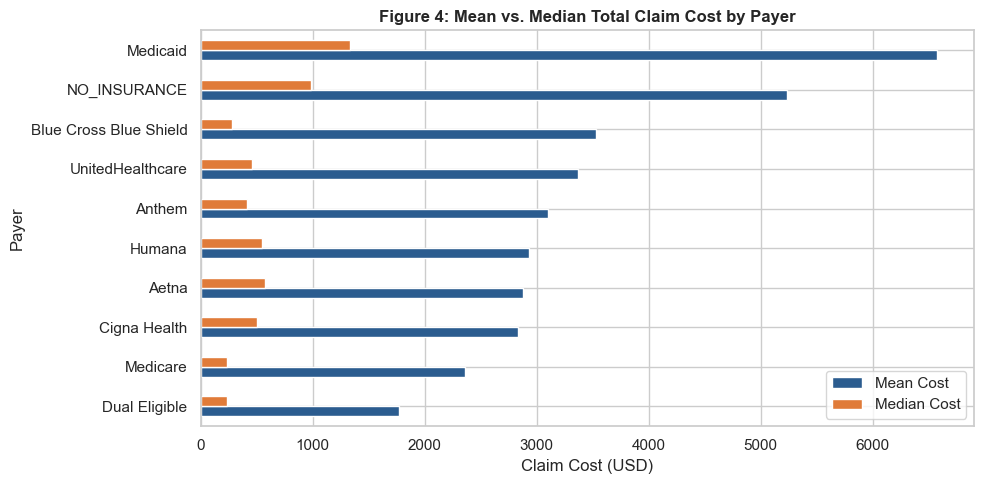

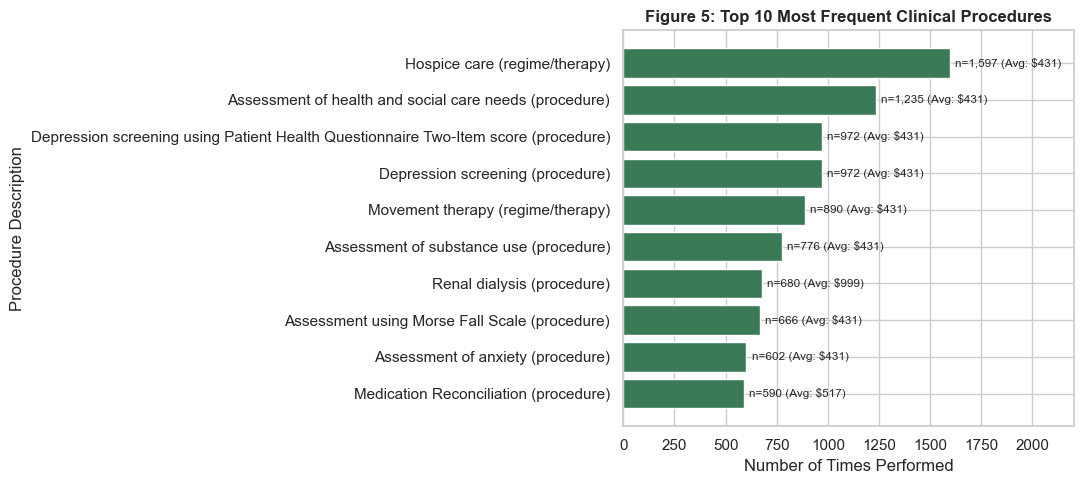

In [6]:
# Figure 4: Mean vs. Median Total Claim Cost by Payer
fig, ax = plt.subplots(figsize=(10, 5))
df.groupby('NAME')['TOTAL_CLAIM_COST'].agg(['mean', 'median']).sort_values('mean').plot(
    kind='barh', ax=ax, color=['#2b5c8f', '#e07b39']
)
ax.set_title('Figure 4: Mean vs. Median Total Claim Cost by Payer', fontweight='bold')
ax.set_xlabel('Claim Cost (USD)')
ax.set_ylabel('Payer')
ax.legend(['Mean Cost', 'Median Cost'])
plt.tight_layout()
plt.savefig('fig4_cost_by_payer.png', dpi=150)
plt.show()

# Figure 5: Top 10 Most Frequent Clinical Procedures
proc_summary = (
    procedures.groupby('DESCRIPTION')
    .agg(count=('BASE_COST', 'count'), mean_cost=('BASE_COST', 'mean'))
    .sort_values('count', ascending=False)
    .head(10)
    .sort_values('count')
)

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(proc_summary.index, proc_summary['count'], color='#3b7a57')
ax.set_title('Figure 5: Top 10 Most Frequent Clinical Procedures', fontweight='bold')
ax.set_xlabel('Number of Times Performed')
ax.set_ylabel('Procedure Description')
for bar, (_, r) in zip(bars, proc_summary.iterrows()):
    ax.text(
        bar.get_width() + 25,
        bar.get_y() + bar.get_height() / 2,
        f"n={int(r['count']):,} (Avg: ${r['mean_cost']:,.0f})",
        va='center',
        fontsize=8.5
    )
ax.set_xlim(0, proc_summary['count'].max() * 1.38)
plt.tight_layout()
plt.savefig('fig5_top_procedures.png', dpi=150)
plt.show()